# The 11% Case File
**Claim under investigation:** *"Recovery has improved by 11% month-on-month."*

This notebook is my working log. I go in the order I actually investigated:
1. Rebuild the data I can trust (golden layer)
2. Find the 11% and check how it was computed
3. Check the seven "suspects" from the brief (A–G)
4. Look for real drivers
5. Counterfactual for the targeting change
6. Where the ₹10 Cr should go

Every finding has an evidence stamp:
`FACT` = directly counted in data · `STRONG` = consistent across several checks · `CORRELATION` = seen together, cause not proven · `HYPOTHESIS` = my best guess, needs testing

> All SQL lives in `/sql`. Run `python run_pipeline.py` first; this notebook only reads the result.

In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
con = duckdb.connect(str(ROOT / 'output' / 'collections.duckdb'), read_only=True)
q = lambda s: con.sql(s).df()
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

C:\Users\LEGION\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 0. First look — what surprised me
Before cleaning I profiled every table (`notebooks/00_profile.py`). Things I did **not** expect:
- Data covers **1 Jan – 8 Aug 2026** (about 7 months, not 12). August is only 8 days.
- Payments table has rows that are **FAILED, PENDING or REVERSED** next to SUCCESS rows.
- 30,000 agent rows but only **1,000 real agents**.
- Three timezones (UTC, IST, Dubai) in the same column.
- **No `client` or `language` column anywhere.** Two of the drivers in the brief cannot be tested. I say this up front instead of inventing a proxy.

## 1. Golden dataset: Raw → Rejected → Golden
Decisions (full detail in `reports/data_quality_report.md`):
- **Payment = recovered only if `SUCCESS`**, after removing repeated `payment_id`s.
- **Agent key = `agent_id`.** `employee_code` is shared by many agents, so it's useless as a key.
- **All call times converted to IST** using the row's timezone label.
- `PTP` and `PROMISE_TO_PAY` merged into one code.

In [2]:
q('select * from dq_waterfall')

,tbl,raw_rows,rejected_duplicates,excluded_not_success,golden_rows,raw_amount,golden_amount
0,payments,25500,500,7466,17534,"1,917,258,617.150","1,315,583,964.640"
1,calls,91350,1350,0,90000,NaN,NaN
2,whatsapp_events,60600,600,0,60000,NaN,NaN
3,borrowers,30600,19585,0,11015,NaN,NaN
4,agents,30000,29000,0,1000,NaN,NaN


In [3]:
w = q("select * from dq_waterfall where tbl='payments'").iloc[0]
print(f"Raw payment rows: {w.raw_rows:,}  ->  golden: {w.golden_rows:,}")
print(f"Raw amount: Rs {w.raw_amount/1e7:,.1f} Cr  ->  golden: Rs {w.golden_amount/1e7:,.1f} Cr  "
      f"({100*(1-w.golden_amount/w.raw_amount):.0f}% of the raw table is NOT real money)")

Raw payment rows: 25,500  ->  golden: 17,534
Raw amount: Rs 191.7 Cr  ->  golden: Rs 131.6 Cr  (31% of the raw table is NOT real money)


`FACT` About **31% of the rupees in the raw payments table never reached the bank** (failed, pending, reversed or duplicated).
If any report sums the raw table, it is overstating recovery by roughly a third.

## 2. Finding the 11%
I expected the 11% to come from duplicates. So I computed month-on-month change on the raw SUCCESS rows, the way a quick report would.

In [4]:
q('select month, is_complete_month, reported_mom_pct, true_total_mom_pct, true_per_day_mom_pct from m_mom')

,month,is_complete_month,reported_mom_pct,true_total_mom_pct,true_per_day_mom_pct
0,2026-01-01,True,NaN,NaN,NaN
1,2026-02-01,True,-8.913,-9.126,0.610
2,2026-03-01,True,10.992,11.032,0.287
3,2026-04-01,True,-7.662,-7.291,-4.201
4,2026-05-01,True,4.832,5.203,1.809
5,2026-06-01,True,-4.450,-4.717,-1.541
6,2026-07-01,True,6.465,6.654,3.214
7,2026-08-01,False,-74.488,-74.840,-2.506


**There it is: Feb → Mar = +10.99%.** That's the reported 11%.

But look at the last column. Per day, March was only **+0.3%** better than February.
February has 28 days, March has 31. Three extra days = +10.7%. **The "improvement" is the calendar.**

I also checked the duplicates: removing them makes the Feb→Mar number go *up* slightly (+11.03%), so duplicates are not what created the 11%.

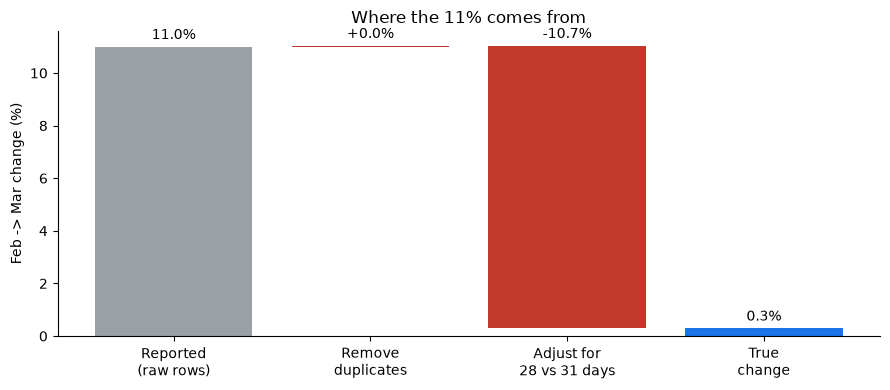

In [5]:
a = q('select * from m_claim_audit')
fig, ax = plt.subplots()
labels = ['Reported\n(raw rows)', 'Remove\nduplicates', 'Adjust for\n28 vs 31 days', 'True\nchange']
vals = [a.value_pct[0], a.change_from_previous[1], a.change_from_previous[2], a.value_pct[2]]
bottoms = [0, a.value_pct[0], a.value_pct[1] + a.change_from_previous[2], 0]
bottoms[2] = a.value_pct[2]
heights = [vals[0], vals[1], -vals[2], vals[3]]
colors = ['#9aa0a6', '#c0392b', '#c0392b', '#1a73e8']
ax.bar(labels, heights, bottom=[0, a.value_pct[0], a.value_pct[2], 0], color=colors)
for i, (b, h) in enumerate(zip([0, a.value_pct[0], a.value_pct[2], 0], heights)):
    ax.text(i, b + h + 0.3, f'{vals[i]:+.1f}%' if i not in (0, 3) else f'{vals[i]:.1f}%', ha='center')
ax.set_ylabel('Feb -> Mar change (%)'); ax.set_title('Where the 11% comes from')
plt.tight_layout(); plt.savefig(FIG / 'claim_audit_waterfall.png', dpi=150); plt.show()

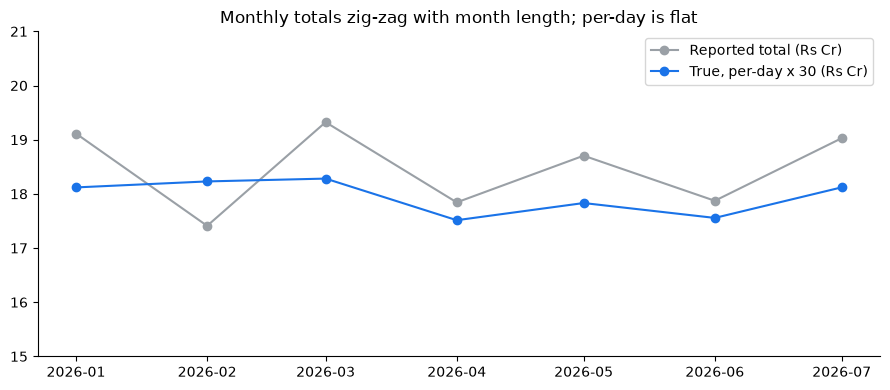

    avg_per_day  month_to_month_noise  trend_per_month
0 5,983,381.307                 0.018           -0.004


In [6]:
m = q('select * from m_monthly where is_complete_month')
fig, ax = plt.subplots()
ax.plot(m.month, m.reported_collected/1e7, marker='o', color='#9aa0a6', label='Reported total (Rs Cr)')
ax.plot(m.month, m.true_collected_per_day*30/1e7, marker='o', color='#1a73e8', label='True, per-day x 30 (Rs Cr)')
ax.set_ylim(15, 21); ax.legend(); ax.set_title('Monthly totals zig-zag with month length; per-day is flat')
plt.tight_layout(); plt.savefig(FIG / 'monthly_trend.png', dpi=150); plt.show()
print(q('''select avg(true_collected_per_day) avg_per_day,
                 stddev(true_collected_per_day)/avg(true_collected_per_day) as month_to_month_noise,
                 regr_slope(true_collected_per_day, epoch(month)/86400/30)/avg(true_collected_per_day) as trend_per_month
          from m_monthly where is_complete_month'''))

`FACT` Per-day recovery has been **flat for 7 months** (~₹60 lakh/day, trend ≈ −0.4% per month, normal month-to-month noise ≈ 1.8%).
The headline zig-zags (−9%, +11%, −8%, +5%, −4%, +7%) are almost entirely 28/30/31-day months.

**Verdict on the claim:** the 11% is arithmetically correct and practically meaningless. The real Feb→Mar change is **+0.3%**, and there is no sustained improvement.

## 3. Rebuilding the metrics
For every metric I put the "easy" definition next to the one I think is right.

In [7]:
q('''select month, contact_rate, rpc_rate, ptp_rate_per_rpc, ptp_rate_if_one_code_missed,
            ptp_kept_rate_naive, ptp_kept_rate_true, recovery_rate_month, recovery_per_account,
            recovery_per_agent_hour, cost_per_rupee from m_monthly''')

,month,contact_rate,rpc_rate,ptp_rate_per_rpc,ptp_rate_if_one_code_missed,ptp_kept_rate_naive,ptp_kept_rate_true,recovery_rate_month,recovery_per_account,recovery_per_agent_hour,cost_per_rupee
0,2026-01-01,0.201,0.772,0.300,0.147,0.476,0.244,0.018,"6,240.971","16,847.100",0.007
1,2026-02-01,0.198,0.763,0.291,0.142,0.497,0.244,0.016,"5,671.415","16,153.659",0.007
2,2026-03-01,0.200,0.780,0.290,0.144,0.497,0.249,0.018,"6,297.079","16,938.915",0.007
3,2026-04-01,0.194,0.768,0.295,0.146,0.509,0.251,0.017,"5,837.935","16,476.421",0.007
4,2026-05-01,0.203,0.774,0.285,0.144,0.503,0.257,0.018,"6,141.676","16,994.880",0.007
5,2026-06-01,0.205,0.773,0.287,0.149,0.483,0.247,0.017,"5,851.991","16,434.868",0.007
6,2026-07-01,0.194,0.777,0.278,0.137,0.491,0.242,0.018,"6,241.409","16,702.177",0.007
7,2026-08-01,0.193,0.778,0.287,0.146,0.508,0.259,0.004,"1,570.323","17,405.274",0.007


| Metric | Easy (misleading) version | My definition | Why |
|---|---|---|---|
| Recovery | Sum of payment rows in the month | SUCCESS, de-duplicated, **per day** | Months have different lengths; failed/reversed money is not recovered |
| Recovery rate | Collected ÷ outstanding of accounts we *worked* | Collected ÷ outstanding of the **whole allocated book** | The worked set changes every month; the book doesn't |
| Contact rate | Answered ÷ all calls (incl. inbound) | Answered **outbound** ÷ outbound dialled | Inbound calls are the borrower calling us, not our reach |
| RPC | Any answered call | Disposition is not NO_CONTACT / WRONG_NUMBER | Answering machine or wrong person isn't a contact |
| PTP rate | Count of code `PTP` | `PTP` + `PROMISE_TO_PAY` ÷ RPC | Counting one code **halves** the PTP rate (0.29 → 0.14) |
| PTP kept | Kept ÷ (kept + broken) | Kept ÷ **all promises that fell due** | Cancelled promises quietly vanish otherwise — **49% vs 25%** |
| Recovery / agent-hour | — | Collected ÷ logged session hours (IST) | Uses real login/logout, not headcount |
| Cost per ₹ | — | Est. contact cost ÷ collected | **No cost data given**: unit costs are my stated assumptions |
| Channel conversion | Last channel before payment gets credit | Touch within **7 days** before payment, vs baseline | Last-touch credits channels for money that came on its own |

`FACT` PTP kept rate is overstated **2x** by the easy definition. `FACT` PTP rate halves if one code version is missed.

## 4. The seven suspects (A–G)

In [8]:
q('select code, suspect, evidence, finding from f_summary')

,code,suspect,evidence,finding
0,A,Duplicate payments,FACT,500 duplicate rows (Rs 3.84 Cr); Rs 57.6 Cr of...
1,B,Attribution errors,FACT,Last-touch credits 67% of payments to a channe...
2,C,Timezone problems,FACT,67% of calls are stored in UTC or Dubai time; ...
3,D,Disposition code changes,FACT,3 code versions run side by side all year; PTP...
4,E,Agent identity,FACT,30000 agent rows -> 1000 real agents; 1099 emp...
5,F,Portfolio mix change,STRONG,Largest monthly swing in any segment share of ...
6,G,Denominator manipulation,STRONG,Rate on worked accounts only is 1.0x the rate ...


**B. Attribution** — how much credit depends on the window?

In [9]:
q('select * from f_b_attribution')

,rule,share_credited
0,"last touch, any time",0.673
1,last touch within 30 days,0.315
2,last touch within 7 days,0.092
3,last touch within 1 day,0.019


In [10]:
q('select * from f_b_campaign_after_end')

,credited_to_campaign,campaign_already_ended,amount_after_end
0,4413,2822,"211,144,070.400"


`FACT` Only **9%** of payments had any contact in the 7 days before. Last-touch-any-time would credit **67%**.
Median gap between last contact and payment is **33 days**. Most money arrives on its own schedule.
`FACT` 2,822 payments (₹21 Cr) would be credited to a campaign that had **already ended**.

**C. Timezones**

In [11]:
q('select * from f_c_timezone')

,source_tz,calls,share_hour_changes,share_day_changes,share_month_changes,outside_hours_raw,outside_hours_ist
0,Asia/Dubai,29996,1.000,0.063,0.002,0.539,0.540
1,Asia/Kolkata,30038,0.000,0.000,0.000,0.547,0.547
2,UTC,29966,1.000,0.230,0.008,0.543,0.540


`FACT` Two-thirds of calls are stored in UTC/Dubai time. After conversion every one of them moves hour, 23% of UTC calls move **day**,
but less than 1% move **month**. So timezones break hour-of-day analysis (best calling time) but **do not explain the 11%**.

**D. Code versions**

In [12]:
q('select * from f_d_codes')

,disposition_version,rows_,coded_ptp,coded_promise_to_pay,first_seen,last_seen
0,legacy,11726,1296,1332,2026-01-01 00:52:49,2026-08-08 23:27:20
1,v1,11620,1285,1309,2026-01-01 00:25:51,2026-08-08 23:04:00
2,v2,11654,1323,1285,2026-01-01 00:10:00,2026-08-08 23:50:50


`FACT` legacy, v1 and v2 codes all run from Jan to Aug at the same time. It's not a one-time switch, it's three systems writing in parallel.

**F. Portfolio mix** and **G. Denominator**

In [13]:
q('select * from f_f_mix_drift limit 6')

,dim,segment,min_share,max_share,drift
0,dpd_bucket,31-60,0.179,0.218,0.039
1,dpd_bucket,1-30,0.346,0.383,0.037
2,risk_segment,HIGH,0.237,0.268,0.031
3,dpd_bucket,90+,0.159,0.189,0.030
4,risk_segment,LOW,0.243,0.269,0.026
5,loan_type,CONSUMER,0.194,0.219,0.024


In [14]:
q('select * from f_g_denominator')

,month,worked_accounts,book_accounts,rate_on_worked_book,rate_on_full_book,terminal_accounts
0,2026-01-01,10293,30000,0.017,0.018,14975
1,2026-02-01,9526,30000,0.016,0.016,14975
2,2026-03-01,10413,30000,0.019,0.018,14975
3,2026-04-01,10040,30000,0.017,0.017,14975
4,2026-05-01,10367,30000,0.017,0.018,14975
5,2026-06-01,9968,30000,0.016,0.017,14975
6,2026-07-01,10285,30000,0.018,0.018,14975
7,2026-08-01,3081,30000,0.004,0.004,14975


In [15]:
q('''select current_status, round(sum(amount)/1e7,1) as rs_cr from g_payments join g_accounts using(account_id) group by 1''')

,current_status,rs_cr
0,WRITEOFF,32.800
1,PAID,32.900
2,ACTIVE,33.300
3,CLOSED,32.600


`STRONG` No real mix shift: no segment's share of collections moves more than ~4 points.

`FACT` **G is real, in a different form than I expected.** Using only "worked" accounts as the denominator, Feb→Mar goes from 1.61% to 1.93%, a **+19%** jump.
The same months on the full book: 1.62% → 1.80%. A worked-book report would make the 11% look even better.

`FACT` **75% of collected money comes from accounts whose status today is CLOSED, PAID or WRITEOFF.** The `accounts.status` field is overwritten to the latest state.
A report that filters on today's status, e.g. "only ACTIVE accounts", would throw away three-quarters of the history. This is the overwritten-history problem.

## 5. Why did it happen? Drivers
### Where did Feb → Mar actually change? (Simpson's-paradox check)

In [16]:
q('select * from a_mix_vs_rate')

,segment,feb,mar,change_per_day,change_pct
0,0,"524,027.739","553,715.593","29,687.854",5.665
1,1-30,"2,104,228.867","2,333,496.110","229,267.243",10.896
2,31-60,"1,174,374.933","1,089,964.658","-84,410.274",-7.188
3,61-90,"1,127,558.383","1,074,555.089","-53,003.294",-4.701
4,90+,"1,146,326.284","1,042,216.099","-104,110.186",-9.082


`FACT` The total per-day number barely moved (+0.3%), but underneath it **1–30 DPD rose +10.9% while every bucket above 30 DPD fell 5–9%.**
The headline hides two opposite movements. Early-stage accounts did better, late-stage did worse.

`HYPOTHESIS` Something shifted effort toward early DPD in March. The data doesn't show what, because campaigns don't map cleanly to DPD.
The cleaner read: early-DPD borrowers pay on their own more often (self-cure), and March was a good self-cure month.

### Jan–Mar vs May–Jul, per day, by segment

In [17]:
q("select * from a_segment_change where dim in ('dpd_bucket','loan_type','risk_segment')")

,dim,segment,per_day_jan_mar,per_day_may_jul,change_pct
0,dpd_bucket,0,"555,980.172","492,912.185",-11.344
1,dpd_bucket,1-30,"2,191,267.976","2,145,705.578",-2.079
2,dpd_bucket,90+,"1,094,228.626","1,080,158.028",-1.286
3,dpd_bucket,31-60,"1,133,752.349","1,123,908.163",-0.868
4,dpd_bucket,61-90,"1,094,808.555","1,102,523.159",0.705
5,loan_type,CREDIT_CARD,"1,261,268.951","1,202,821.413",-4.634
6,loan_type,AUTO,"1,238,180.272","1,191,284.283",-3.787
7,loan_type,BNPL,"1,163,217.785","1,138,777.419",-2.101
8,loan_type,PERSONAL,"1,179,941.298","1,177,923.896",-0.171
9,loan_type,CONSUMER,"1,227,429.372","1,234,400.101",0.568


In [18]:
q("select * from a_segment_change where dim = 'state'")

,dim,segment,per_day_jan_mar,per_day_may_jul,change_pct
0,state,West Bengal,"582,332.441","529,333.426",-9.101
1,state,Rajasthan,"557,541.898","519,103.672",-6.894
2,state,Delhi,"576,928.635","542,622.988",-5.946
3,state,Tamil Nadu,"547,464.101","517,105.263",-5.545
4,state,Maharashtra,"1,110,869.339","1,068,105.434",-3.850
5,state,Odisha,"601,576.610","584,881.114",-2.775
6,state,Telangana,"558,779.841","544,669.645",-2.525
7,state,Haryana,"486,292.877","506,632.997",4.183
8,state,Karnataka,"507,416.588","539,546.190",6.332
9,state,UNKNOWN,"540,835.348","593,206.383",9.683


`CORRELATION` Between halves, most segments drift down 1–5%. The biggest drops: DPD-0 (−11%), West Bengal (−9%), NPA (−7%).
Karnataka and Haryana are slightly up. These moves are within 2–3x the normal monthly noise, so I treat them as weak signals, not results.

### Operational drivers

In [19]:
q('select * from a_vendor')

,vendor_id,vendor_name,vendor_status,calls,answer_rate,fail_rate
0,VND0000014,Knowlarity,INACTIVE,5559,0.211,0.193
1,VND0000006,Knowlarity,ACTIVE,5452,0.205,0.200
2,VND0000013,Knowlarity,ACTIVE,5414,0.204,0.200
3,VND0000010,Airtel,INACTIVE,5698,0.204,0.195
4,VND0000011,Airtel,ACTIVE,5577,0.202,0.200
5,VND0000003,Twilio,INACTIVE,5484,0.199,0.204
6,VND0000015,TataTele,ACTIVE,5625,0.198,0.204
7,VND0000008,Airtel,INACTIVE,5436,0.198,0.203
8,VND0000002,Exotel,INACTIVE,5465,0.197,0.206
9,VND0000012,Airtel,INACTIVE,5570,0.196,0.195


In [20]:
q('select * from a_attempts')

,calls_in_month,account_months,pay_rate
0,1,57102,0.077
1,2,11909,0.079
2,3,1700,0.067
3,4,172,0.070
4,5+,10,0.200


In [21]:
q('select * from a_tenure'), q('select * from a_agent_spread')

(      tenure   ptps  kept_rate
 0  1-2 years    952      0.253
 1   2+ years  17048      0.249,
     p10   p50   p90  avg_ptps_per_agent
 0 0.125 0.240 0.385              18.000)

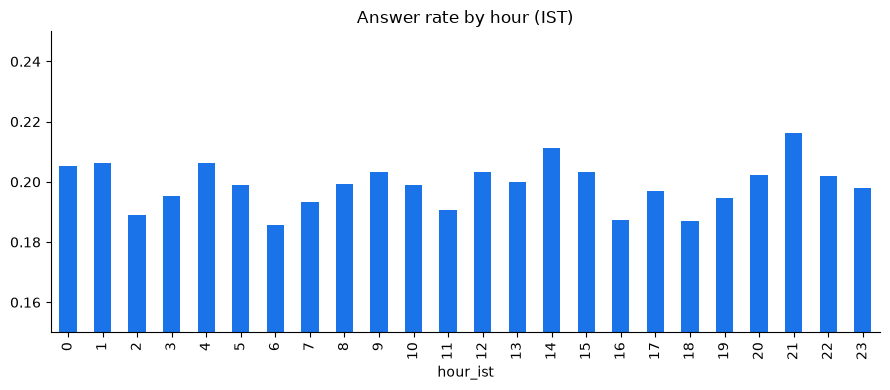

In [22]:
h = q('select * from a_hour')
ax = h.plot.bar(x='hour_ist', y='answer_rate', legend=False, color='#1a73e8'); ax.set_ylim(0.15, 0.25)
ax.set_title('Answer rate by hour (IST)'); plt.tight_layout(); plt.savefig(FIG / 'answer_by_hour.png', dpi=150); plt.show()

| Driver | What I found | Stamp |
|---|---|---|
| Telephony vendor | Answer rate 19.2%–21.1% across 15 vendor accounts; inactive vendors still carry calls | `CORRELATION` (spread ≈ noise) |
| Calling time | Answer rate flat by hour (18.6–21.6%), ~54% of calls outside 8am–7pm | `FACT` (compliance risk) |
| Attempt frequency | 1 call → 7.7% pay, 2 → 7.9%, 3–4 → ~7%. More calls ≠ more payment | `CORRELATION` |
| Agent tenure | 95% of PTPs from 2+ year agents, so tenure can't be tested | `FACT` (data limit) |
| Agent | Kept-rate p10 12.5% vs p90 38%, but only ~18 PTPs per agent, so mostly noise | `HYPOTHESIS` |
| Portfolio mix / DPD / segment | No mix shift; within-bucket rates moved in opposite directions | `STRONG` |
| Client, language | **Not in the data** | — |

**Honest summary:** I could not find an operational lever that clearly moved recovery. The biggest "driver" of the 11% is the calendar.

## 6. Counterfactual: what if targeting had not changed?
**Setup** (the brief tells us to assume a mid-year change):
- **Change date:** 1 Apr 2026, when v3-strategy campaigns took over targeting.
- **Treated:** accounts targeted by a v3 campaign from April.
- **Control:** accounts never targeted by v3. Accounts hit by v3 *before* April are dropped (contaminated).
- **Method:** difference-in-differences on ₹ collected per account per day.
  `effect = (treated after − treated before) − (control after − control before)`

In [23]:
d = q('select * from a_did').set_index('grp')
t, c = d.loc['treated'], d.loc['control']
did = (t.post_rs_per_acct_day - t.pre_rs_per_acct_day) - (c.post_rs_per_acct_day - c.pre_rs_per_acct_day)
print(d); print(f'\nDiD effect: Rs {did:.1f} per account per day  ({100*did/t.pre_rs_per_acct_day:+.1f}%)')
print(f'Implied extra recovery Apr-Jul: Rs {did*t.accounts*122/1e7:.1f} Cr')

         accounts  pre_rs_per_acct_day  post_rs_per_acct_day
grp                                                         
control     20172              203.735               197.873
treated      5247              195.019               195.653

DiD effect: Rs 6.5 per account per day  (+3.3%)
Implied extra recovery Apr-Jul: Rs 0.4 Cr


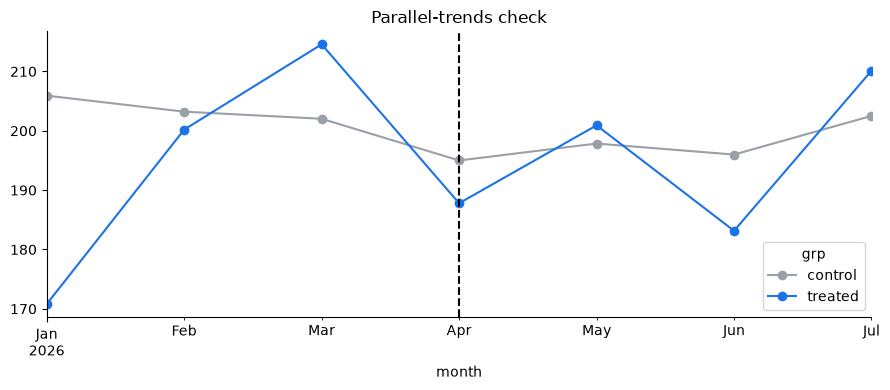

In [24]:
dm = q('select * from a_did_monthly').pivot(index='month', columns='grp', values='rs_per_acct_day')
ax = dm.plot(marker='o', color={'control':'#9aa0a6','treated':'#1a73e8'})
ax.axvline(pd.Timestamp('2026-04-01'), ls='--', color='k'); ax.set_title('Parallel-trends check')
plt.tight_layout(); plt.savefig(FIG / 'did_parallel_trends.png', dpi=150); plt.show()

`HYPOTHESIS` The DiD estimate is about **+₹6.5 per account per day (+3%)**, i.e. only ~₹0.4 Cr over Apr–Jul on a ₹73 Cr base.

**But I don't trust it**, and the chart shows why: before April, the treated group was already climbing (₹171 → ₹215) while control was flat.
**Parallel trends fail.** The treated line also jumps ±₹15 month to month, which is bigger than the effect itself.

So: *without the targeting change, recovery would most likely have looked about the same.* The monthly noise (±₹15 per account per day) is twice the effect (₹6.5), so zero is well inside the plausible range.

**What would make this reliable:** a randomised holdout. Keep 10% of eligible accounts on old targeting for 8 weeks. That's the experiment I recommend in the next section.

Confounders I could not control: who chose which accounts get v3 (selection bias), concurrent campaigns, and self-cure timing.

## 7. Where should ₹10 Cr go?

In [25]:
q('select * from a_channel_uplift')

,channel,touches,pay_rate_7d,baseline_pay_rate_7d,uplift_pts,incremental_rs_per_touch
0,VOICE,17216,0.020,0.019,0.001,182.858
1,SMS,21537,0.019,0.019,0.001,29.962
2,WHATSAPP,28763,0.019,0.019,0.000,19.825
3,FIELD,16042,0.017,0.019,-0.002,-89.364


In [26]:
yr = q('select avg(true_collected_per_day)*365 as annual from m_monthly where is_complete_month').annual[0]
print(f'Annual recovery run-rate: Rs {yr/1e7:.0f} Cr')
print(f'To pay back Rs 10 Cr in 12 months, an option must lift recovery by {100*1e8/yr:.1f}%')
cost = q('select avg(est_cost)*12 c from m_monthly where is_complete_month').c[0]
print(f'Estimated annual contact cost (my assumptions): Rs {cost/1e7:.1f} Cr')

Annual recovery run-rate: Rs 218 Cr
To pay back Rs 10 Cr in 12 months, an option must lift recovery by 4.6%
Estimated annual contact cost (my assumptions): Rs 1.6 Cr


**The bar:** any option must lift recovery by **~4.5%** to pay back ₹10 Cr in a year.

**What the data says about each option:**
- *More agents / AI voice / telephony:* more contact doesn't create payment. Calling 2x vs 1x gives the same pay rate, and voice uplift is +0.14 pts (about 1.3 standard errors, not significant).
- *WhatsApp / SMS:* uplift of +0.03 to +0.06 pts. Cheap, but tiny.
- *Field:* negative uplift (visits go to accounts that were less likely to pay anyway: selection bias).
- *Targeting:* 91% of payments arrive with no contact in the previous 7 days. We are spending effort on people who would pay anyway and not reaching the ones who don't.

### Recommendation: **Better borrower targeting**, released in stages
1. **₹0.8 Cr, weeks 0–10:** clean data foundation (this pipeline) + a randomised 90/10 holdout test of a new targeting model.
2. **Gate:** release the remaining ₹9.2 Cr only if the test shows ≥3% recovery lift at 95% confidence.

| | Downside | Base | Upside |
|---|---|---|---|
| Recovery lift | 0% | 2.5% | 5% |
| Extra recovery / year | ₹0 | ~₹5.5 Cr | ~₹11 Cr |
| Spend | ₹0.8 Cr (stopped at gate) | ₹10 Cr | ₹10 Cr |
| 1st-year ROI | −100% of ₹0.8 Cr | −45% | +10% |
| Break-even | never (but only ₹0.8 Cr lost) | ~22 months | ~11 months |

`HYPOTHESIS` The lift numbers are **assumptions**, not measurements. Industry targeting projects typically report 2–5%.
**I'm being explicit: this data is not good enough to justify spending ₹10 Cr on anything up front.**
The recommendation is to buy the evidence first (₹0.8 Cr), because it protects ₹9.2 Cr.

Why targeting over the others: it's the only option that improves *every* channel, the cheapest to test, and fully reversible.

## 8. What I could be wrong about
- **I assumed payments without a timezone column are IST.** If they're UTC, ~23% of payments shift day, but <1% shift month, so the verdict holds.
- **Unit costs are my guesses.** Cost-per-₹ is directional only.
- **The targeting change date (1 Apr) is my choice.** A different date changes the DiD number, but not the parallel-trends failure.
- **The data looks synthetic and very uniform** (almost every category is split ~20/20/20/20/20). Real data would have much stronger segment differences, and the driver analysis would say more.
- I treated `payment_reference` collisions as different payments because account, amount and date differ. If they're actually split payments, nothing changes, because they're all still real money.

## My investigation log
**Step 1: Look before cleaning.** I profiled every table first. Two surprises: the data covers only 1 Jan – 8 Aug 2026, not 12 months, and almost every category is split evenly (statuses, channels, outcomes all ~20% each). That made me expect a flat business, not a growing one.

**Step 2: Guess the cause, then test it.** My first guess was that duplicate payments created the 11%. Wrong. Removing the 500 duplicate rows moved Feb→Mar from 10.99% to 11.03%, because the duplicates are spread evenly across months.

**Step 3: Find the exact 11%.** I computed month-on-month change for every month on raw SUCCESS payments. Only Feb→Mar gives 11.0%. Then I noticed February has 28 days and March 31. Per day, the change is +0.3%. This was the key moment of the analysis.

**Step 4: Check the other suspects anyway.** Even after finding the cause, I went through all seven checks from the brief. Two results surprised me: only 9% of payments had any contact in the 7 days before, and 75% of collected money comes from accounts whose current status is closed, paid or written off. Both would mislead a report even though neither caused the 11%.

**Step 5: Look underneath the flat total.** Splitting Feb→Mar by DPD bucket showed 1–30 DPD up 11% and 30+ DPD down 5–9%. The total hid two opposite movements.

**Step 6: Try the counterfactual, and not trust it.** The before/after comparison for the targeting change gave +3%, but the parallel-trends chart showed the treated group was already rising before April. I reported the number and said why it isn't reliable.

**Step 7: Be honest about the ₹10 Cr.** No lever in the data clearly moves recovery, so instead of forcing a big ROI number I recommended paying ₹0.8 Cr for a proper test before committing the rest.

**What I'd do with more time:**
- Rebuild point-in-time DPD from the status history instead of using the current DPD.
- Get real cost data instead of my unit-cost assumptions.
- Ask the data owners how payment reversals link to the original payment.
- Confirm the timezone of the payments table, which I assumed was IST.